# Support Vector Machine

Hai đội lập trình đứng ở hai phía của một vạch sân. Có nhiều vị trí đặt vạch mà vẫn tách được hai đội, nhưng ta thích vạch còn đủ khoảng trống hai bên để một người bước lệch chút vẫn không bị xếp sai. Support Vector Machine (SVM) biến trực giác khoảng trống đó thành bài toán tối ưu. Ta sẽ tính lề trên giấy trước, rồi mới dùng kernel để tạo vạch cong.

> **Mục tiêu sau bài này**
>
> - Tính signed score, khoảng cách và hinge loss của một điểm.
> - Giải thích C, gamma và tác dụng của chuẩn hóa.
> - Dùng Pipeline/CV với SVC và phân biệt decision score với xác suất.

## Lề lớn nhất

Gán nhãn $y_i \in \{-1, +1\}$. Một siêu phẳng $\mathbf{w}^\top\mathbf{x} + b = 0$ phân loại đúng mọi điểm khi $y_i(\mathbf{w}^\top\mathbf{x}_i + b) > 0$. Khoảng cách từ $\mathbf{x}_i$ đến siêu phẳng là

$$\frac{\lvert \mathbf{w}^\top\mathbf{x}_i + b\rvert}{\lVert\mathbf{w}\rVert}.$$

Vì nhân $\mathbf{w}$ và $b$ với cùng một số dương không đổi siêu phẳng, ta chuẩn hóa sao cho các điểm gần nhất thỏa $y_i(\mathbf{w}^\top\mathbf{x}_i + b) = 1$. Khi đó độ rộng lề (margin) giữa hai phía là $2/\lVert\mathbf{w}\rVert$, và cực đại lề tương đương

$$\min_{\mathbf{w},\, b}\ \frac{1}{2}\lVert\mathbf{w}\rVert^2 \quad \text{thỏa}\quad y_i\left(\mathbf{w}^\top\mathbf{x}_i + b\right) \ge 1,\ \ i = 1, \dots, n.$$

Đây là bài toán tối ưu lồi bậc hai: khi dữ liệu tách được thì có nghiệm, và không có cực tiểu địa phương nào để mắc kẹt. Các điểm nằm đúng trên biên lề là **vector hỗ trợ** (support vectors). Trong biểu diễn đối ngẫu, các điểm có hệ số khác 0 đóng góp vào hàm quyết định; với soft margin chúng có thể nằm trong lề hoặc bị phân loại sai.

Cụ thể, nghiệm có dạng $\mathbf{w} = \sum_i \alpha_i y_i \mathbf{x}_i$, trong đó $\alpha_i > 0$ chỉ ở vector hỗ trợ: hai vector $(1, 1)$ nhãn $+1$ và $(-1, -1)$ nhãn $-1$, cùng $\alpha = 1$, cho $\mathbf{w} = (2, 2)$. Bỏ một điểm không phải vector hỗ trợ thì nghiệm không đổi, nên lỗi leave-one-out không vượt quá tỉ lệ vector hỗ trợ trên tổng số điểm. Trên trục số với nhãn $+1$ ở $1, 3$ và $-1$ ở $-1$, lề nằm giữa hai điểm khác nhãn gần nhau nhất: ranh giới ở 0, $w = 1$, $b = 0$. Thêm một đặc trưng mới không làm lề hẹp đi, vì đặt trọng số 0 cho nó vẫn là một nghiệm hợp lệ.



**Hỏi nhanh.** Sau khi chuẩn hóa, hai biên lề $f(\mathbf x) = \pm 1$ cách nhau đúng 1 đơn vị. $\lVert\mathbf w\rVert$ bằng bao nhiêu?

- A. $0.5$
- B. $1$
- C. $4$
- D. $2$

<details><summary>Đáp án</summary>

D. $2$

Độ rộng lề là $2/\lVert\mathbf w\rVert = 1$, nên $\lVert\mathbf w\rVert = 2$. Lề rộng thì $\mathbf w$ nhỏ, và đó là lý do bài toán đi tìm cực tiểu của $\frac12\lVert\mathbf w\rVert^2$.

</details>

## Lề mềm và hinge loss

Dữ liệu thật hiếm khi tách được hoàn toàn. Lề mềm (soft margin) cho phép vi phạm, có trả giá:

$$\min_{\mathbf{w},\, b}\ \frac{1}{2}\lVert\mathbf{w}\rVert^2 + C\sum_{i=1}^{n}\max\!\big(0,\ 1 - y_i f(\mathbf{x}_i)\big), \qquad f(\mathbf{x}) = \mathbf{w}^\top\mathbf{x} + b.$$

Số hạng thứ hai là hinge loss: bằng 0 nếu điểm nằm đúng phía và ngoài lề, tăng tuyến tính nếu lấn vào lề hoặc sang phía sai. Lại là “phạt + lỗi”, chỉ khác là hệ số đặt ở phía lỗi: $C$ lớn thì ít chịu vi phạm, lề hẹp, dễ overfit; $C$ nhỏ thì lề rộng, mô hình đơn giản hơn.



So với logistic regression ở bài 2.3, hai mô hình chỉ khác hàm mất mát. Log loss không bao giờ bằng 0, nên mọi điểm đều góp tiếng nói. Hinge loss bằng 0 với điểm “an toàn”, nên chỉ các điểm gần ranh giới mới quan trọng.

**Hỏi nhanh.** Cho $C$ tiến dần về 0 trong bài toán lề mềm. Nghiệm có xu hướng thế nào?

- A. Lề hẹp lại, cố phân loại đúng mọi điểm train
- B. $\mathbf w$ về gần 0, lề rất rộng, bỏ qua các vi phạm
- C. Không đổi, vì $C$ chỉ ảnh hưởng tốc độ tối ưu
- D. Trở thành SVM lề cứng, không chấp nhận vi phạm

<details><summary>Đáp án</summary>

B. $\mathbf w$ về gần 0, lề rất rộng, bỏ qua các vi phạm

Khi $C \to 0$, vi phạm gần như không bị tính phí, nên mục tiêu chỉ còn là làm $\lVert\mathbf w\rVert$ nhỏ. Lề rất rộng và gần như bỏ mặc dữ liệu, tức là underfit. Ngược lại, $C \to \infty$ mới tiến tới lề cứng.

</details>

## Mẹo kernel

Muốn ranh giới cong, cách thô là ánh xạ $\mathbf{x}$ sang không gian đặc trưng lớn hơn $\phi(\mathbf{x})$ rồi chạy SVM tuyến tính ở đó. Điều đặc biệt là dạng đối ngẫu (dual) của bài toán SVM chỉ dùng dữ liệu qua tích vô hướng $\phi(\mathbf{x}_i)^\top\phi(\mathbf{x}_j)$. Nếu có hàm $k$ tính thẳng tích đó, gọi là kernel, thì không bao giờ phải tạo $\phi$:

$$k(\mathbf{x}, \mathbf{z}) = \phi(\mathbf{x})^\top \phi(\mathbf{z}).$$



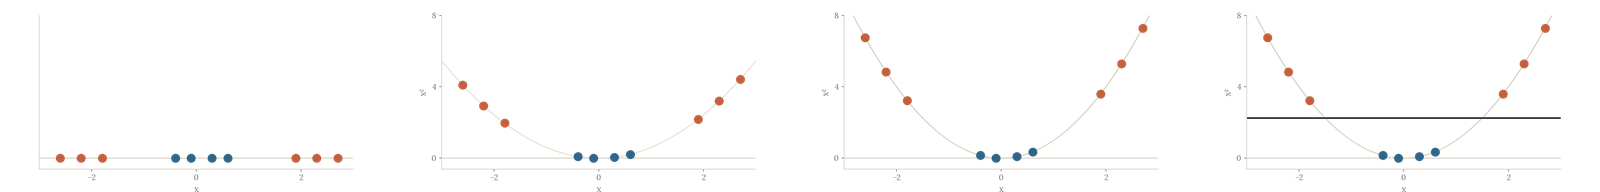

Ví dụ với $\mathbf{x}, \mathbf{z} \in \R^2$ và $\phi(\mathbf{x}) = \left(x_1^2,\ \sqrt{2}\,x_1x_2,\ x_2^2\right)$:

$$\phi(\mathbf{x})^\top\phi(\mathbf{z}) = x_1^2z_1^2 + 2x_1x_2z_1z_2 + x_2^2z_2^2 = \left(\mathbf{x}^\top\mathbf{z}\right)^2.$$

Một phép nhân vô hướng rồi bình phương thay cho việc lập và nhân hai vector ba chiều. Với kernel RBF (Gaussian)

$$k(\mathbf{x}, \mathbf{z}) = \exp\!\left(-\gamma\,\lVert\mathbf{x} - \mathbf{z}\rVert^2\right),$$

không gian đặc trưng tương ứng có vô hạn chiều, vậy mà tính kernel chỉ tốn $O(d)$.

**Hỏi nhanh.** Với $\mathbf x \in \R^{1000}$, kernel $(\mathbf x^\top\mathbf z)^2$ ứng với một $\phi$ có khoảng bao nhiêu chiều? Tính thẳng kernel thì tốn khoảng bao nhiêu phép nhân?

- A. 2000 chiều, khoảng 2000 phép nhân
- B. 1 000 000 chiều, khoảng 1 000 000 phép nhân
- C. 500 500 chiều, khoảng 500 500 phép nhân
- D. 500 500 chiều, khoảng 1000 phép nhân

<details><summary>Đáp án</summary>

D. 500 500 chiều, khoảng 1000 phép nhân

$\phi$ gồm mọi tích $x_ix_j$ với $i \le j$, tức $1000\cdot 1001/2 = 500\,500$ chiều. Còn kernel chỉ cần một tích vô hướng 1000 chiều rồi bình phương. Toàn bộ “mẹo kernel” nằm ở đây: làm việc trong một không gian khổng lồ mà không phải bước vào đó.

</details>

Hàm dự đoán khi đó có dạng $f(\mathbf{x}) = \sum_{i \in SV} \alpha_i y_i\, k(\mathbf{x}_i, \mathbf{x}) + b$: một tổng có trọng số theo độ giống giữa điểm mới và các vector hỗ trợ. Nhìn kỹ thì giống kNN có trọng số, nhưng trọng số được học bằng tối ưu. Với RBF và $\gamma = 0.1$, hai điểm $(1, 2)$ và $(4, 6)$ có $\lVert\mathbf{x} - \mathbf{z}\rVert^2 = 25$ nên $k = e^{-2.5} \approx 0.082$. Một điểm test ở rất xa mọi vector hỗ trợ có mọi $k$ gần 0, nên $f$ gần bằng $b$ và dấu của $b$ quyết định nhãn.

Kernel đa thức $(\mathbf{x}^\top\mathbf{z} + c)^p$ có thêm hằng số $c > 0$ thì gồm mọi đơn thức tới bậc $p$: với hai chiều và $p = 2$ là 6 tọa độ $1, x_1, x_2, x_1^2, x_1x_2, x_2^2$. Trên một trục, hàm quyết định khi đó là đa thức bậc $p$, nên đổi dấu nhiều nhất $p$ lần. Mẹo kernel không riêng gì SVM: thuật toán nào chỉ dùng dữ liệu qua tích vô hướng đều đổi được sang kernel, như Ridge ở bài 2.2 viết dưới dạng đối ngẫu là giải $(K + \lambda I)\mathbf{a} = \mathbf{y}$ cỡ $n \times n$.

## Hai tham số C và γ

Với kernel RBF, $\gamma$ quy định “tầm ảnh hưởng” của mỗi vector hỗ trợ. $\gamma$ lớn thì mỗi điểm chỉ ảnh hưởng vùng rất nhỏ quanh nó, ranh giới uốn lượn theo từng điểm. $\gamma$ nhỏ thì ranh giới mượt gần như tuyến tính. Cùng với $C$, đây là hai núm cần dò, luôn trên lưới logarit, ví dụ $C \in \{0.1, 1, 10, 100\}$ và $\gamma \in \{10^{-3}, \dots, 1\}$.



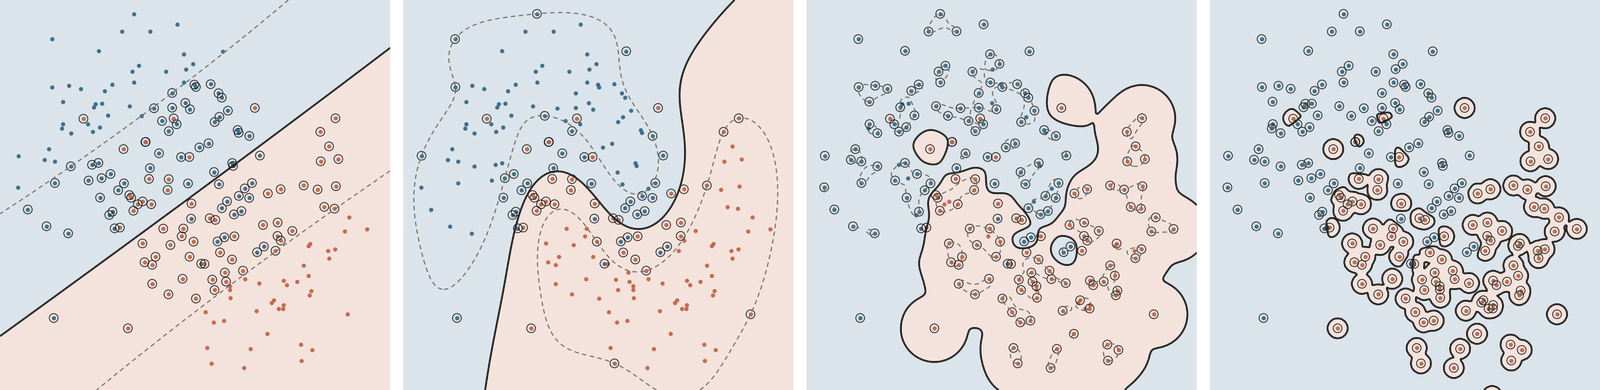

SVM RBF nhạy với khoảng cách; khi các cột khác đơn vị, hãy chuẩn hóa trong Pipeline và kiểm bằng validation.

**Hỏi nhanh.** SVM với kernel RBF, $\gamma = 100$, đúng 100% trên train nhưng cross-validation chỉ được 70%. Ta nên thử gì trước?

- A. Tăng $\gamma$ lên 1000 cho ranh giới khít hơn
- B. Tăng $C$ để phạt vi phạm nặng hơn nữa
- C. Giảm $\gamma$, và thử cả $C$ nhỏ hơn
- D. Bỏ chuẩn hóa để giữ đơn vị gốc của dữ liệu

<details><summary>Đáp án</summary>

C. Giảm $\gamma$, và thử cả $C$ nhỏ hơn

$\gamma$ lớn khiến mỗi vector hỗ trợ chỉ ảnh hưởng tới một vùng rất nhỏ, nên ranh giới uốn theo từng điểm train. Đó là dấu hiệu overfit. Giảm $\gamma$ làm ranh giới mượt hơn, còn $C$ nhỏ hơn thì nới rộng lề. Tăng $\gamma$ hay tăng $C$ là đi ngược hướng.

</details>

## Ví dụ tính tay

Siêu phẳng $\mathbf{w} = (3, 4)$, $b = -10$, nên $\lVert\mathbf{w}\rVert = 5$ và độ rộng lề $2/5 = 0.4$.

- Điểm $(2, 1)$: $3\cdot2 + 4\cdot1 - 10 = 0$, nằm đúng trên siêu phẳng.
- Điểm $(3, 2)$ nhãn $+1$: $f = 7$, khoảng cách $7/5 = 1.4$, $y f = 7 \ge 1$, hinge loss bằng 0.
- Điểm $(2, 1.1)$ nhãn $+1$: $f = 0.4$, nằm đúng phía nhưng trong lề, hinge loss $= 1 - 0.4 = 0.6$.



## Chi phí và giới hạn

- Huấn luyện SVM có kernel tốn khoảng $O(n^2)$ đến $O(n^3)$ với chi phí phụ thuộc dữ liệu và solver; bộ nhớ còn phụ thuộc cơ chế cache. Quá vài chục nghìn mẫu là bắt đầu đuối.
- Với dữ liệu lớn, thưa, nhiều chiều như văn bản, dùng SVM tuyến tính (`LinearSVC`): rất nhanh và rất tốt.
- SVM không cho xác suất. `SVC(probability=True)` hiệu chỉnh thêm bằng Platt scaling, chậm hơn và không hoàn hảo.

**Hỏi nhanh.** Cần phân loại 2 triệu bình luận, mỗi bình luận là một vector TF-IDF 100 000 chiều, rất thưa. Nên thử mô hình nào trước?

- A. `LinearSVC` hoặc logistic regression tuyến tính
- B. `SVC(kernel="rbf")`, vì ranh giới cong thì mạnh hơn
- C. `SVC(kernel="poly", degree=5)` cho đủ phức tạp
- D. kNN với $k = 1$ trên toàn bộ vector TF-IDF

<details><summary>Đáp án</summary>

A. `LinearSVC` hoặc logistic regression tuyến tính

Kernel SVM tốn cỡ $O(n^2)$ trở lên theo số mẫu, không chạy nổi với 2 triệu mẫu. Văn bản nhiều chiều thường đã gần tách được bằng một siêu phẳng, và `LinearSVC` xử lý vector thưa rất nhanh. Còn 1-NN trên 2 triệu vector thì mỗi lần dự đoán phải quét cả kho.

</details>

## Đọc score trước khi đọc xác suất

Với $\mathbf w=(3,4)$, $b=-10$, $\lVert\mathbf w\rVert=5$. Mỗi điểm có score $f(\mathbf x)=\mathbf w^\top\mathbf x+b$; dấu quyết định phía của vạch, còn $\lvert f\rvert/5$ mới là khoảng cách hình học. Score 7 không có nghĩa xác suất 70%, vì score có đơn vị phụ thuộc cách đặt $\mathbf w$. Hinge loss lại dùng **nhãn có dấu** $y\in\{-1,+1\}$; nếu lấy nhãn 0/1 nhân vào công thức, mọi mẫu lớp 0 đều có loss 1, là một lỗi âm thầm.

In [ ]:
import numpy as np

w_margin = np.array([3., 4.])
b_margin = -10.
points_margin = np.array([[2., 1.], [3., 2.], [2., 1.1]])
labels_signed = np.array([1., 1., 1.])
scores = points_margin @ w_margin + b_margin
distances = np.abs(scores) / np.linalg.norm(w_margin)
hinge = np.maximum(0., 1. - labels_signed * scores)
print("score:", scores.round(3).tolist())
print("khoảng cách:", distances.round(3).tolist())
print("hinge:", hinge.round(3).tolist())

score: [0.0, 7.0, 0.4]
khoảng cách: [0.0, 1.4, 0.08]
hinge: [1.0, 0.0, 0.6]


Dòng thứ ba tách hai khái niệm: điểm score 0.4 được phân loại đúng phía nhưng vẫn chịu loss 0.6 vì nằm trong lề; điểm score 7 thì loss 0. Điểm nằm ngay trên vạch có score 0, cần quy ước phá hòa khi biến thành nhãn. Thư viện lo phần ấy, nhưng code tay cần ghi rõ.



**Hỏi nhanh.** Một mẫu có $y = -1$ và $f(\mathbf x) = -0.2$. Hinge loss bằng bao nhiêu?

- A. 1.2
- B. 0.8
- C. 0
- D. 0.2

<details><summary>Đáp án</summary>

B. 0.8

Signed margin là $(-1)\cdot(-0.2) = 0.2$, nên loss là $\max(0, 1 - 0.2) = 0.8$. Mẫu nằm đúng phía nhưng chưa ra khỏi lề.

</details>

## Kernel là một phép đo giống nhau có cấu trúc

Không phải bất kỳ hàm “độ giống” nào cũng làm kernel hợp lệ cho SVM. Kernel hợp lệ là tích vô hướng sau một phép biến đổi $\phi$ nào đó, nên ma trận Gram $K_{ij} = k(\mathbf x_i, \mathbf x_j)$ luôn đối xứng và nửa xác định dương: với mọi vector $\mathbf a$, $\mathbf a^\top K\mathbf a \ge 0$. Kernel tuyến tính, đa thức và RBF đều thỏa. Một hàm tự đặt ra thì phải kiểm điều kiện này trước khi gọi nó là kernel.

**Hỏi nhanh.** $k(\mathbf x, \mathbf z) = \mathbf x^\top\mathbf z + 1$ có phải là một kernel hợp lệ không?

- A. Không, vì cộng hằng số làm mất tích vô hướng
- B. Có, nhưng chỉ khi $\mathbf x$ và $\mathbf z$ không âm
- C. Không, vì kernel phải nằm trong đoạn $[0, 1]$
- D. Có, với $\phi(\mathbf x) = (\mathbf x, 1)$

<details><summary>Đáp án</summary>

D. Có, với $\phi(\mathbf x) = (\mathbf x, 1)$

Thêm vào mỗi vector một tọa độ bằng 1: $(\mathbf x, 1)^\top(\mathbf z, 1) = \mathbf x^\top\mathbf z + 1$. Đã có $\phi$ thì là kernel hợp lệ, không cần điều kiện về dấu. Kernel tuyến tính và kernel đa thức vốn không bị chặn trong $[0, 1]$.

</details>

Ta kiểm ví dụ polynomial trong bài bằng cả hai cách: dựng đặc trưng ba chiều rồi tính tích vô hướng, và bình phương tích vô hướng hai chiều.

In [ ]:
x_kernel = np.array([1., 2.])
z_kernel = np.array([3., 4.])
def phi2(v):
    a, b = v
    return np.array([a * a, np.sqrt(2.) * a * b, b * b])

print(round(float(phi2(x_kernel) @ phi2(z_kernel)), 6))
print(float((x_kernel @ z_kernel) ** 2))
assert np.allclose(phi2(x_kernel) @ phi2(z_kernel), (x_kernel @ z_kernel) ** 2)

121.0
121.0


Hai dòng cùng bằng 121. Ta tính được kernel mà không dựng từng tọa độ của không gian lớn hơn. Cái giá chuyển sang số mẫu: kernel SVM làm việc với quan hệ giữa các cặp mẫu, nên thời gian và bộ nhớ tăng nhanh theo $n$. Hãy đo trên một phần nhỏ dữ liệu trước khi fit cả bộ.

## Dùng thư viện

In [ ]:
from sklearn.datasets import make_moons
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

X, y = make_moons(n_samples=500, noise=0.25, random_state=0)
model = make_pipeline(StandardScaler(), SVC(kernel="rbf"))
grid = GridSearchCV(model, {"svc__C": [0.1, 1, 10, 100], "svc__gamma": [0.01, 0.1, 1, 10]}, cv=5)
grid.fit(X, y)
print(grid.best_params_, round(grid.best_score_, 3))
print("số vector hỗ trợ:", grid.best_estimator_[-1].n_support_.sum(), "trên", len(X))

{'svc__C': 1, 'svc__gamma': 10} 0.936
số vector hỗ trợ: 221 trên 500


**Hỏi nhanh.** Mô hình tốt nhất dùng 221 trên 500 điểm làm vector hỗ trợ. Con số này nói lên điều gì?

- A. Mô hình học thuộc 221 điểm nên chắc chắn overfit
- B. 279 điểm còn lại bị bỏ đi vì gán nhãn sai
- C. Hai lớp chồng lên nhau, nhiều điểm nằm trong lề
- D. Lề cứng đã tách được hoàn toàn hai lớp

<details><summary>Đáp án</summary>

C. Hai lớp chồng lên nhau, nhiều điểm nằm trong lề

Với nhiễu 0.25, hai mặt trăng chồng lên nhau ở rìa, nên nhiều điểm nằm trong lề hoặc ở sai phía. Với lề mềm, tất cả những điểm ấy đều là vector hỗ trợ. Hệ quả thực tế là mỗi lần dự đoán phải tính kernel với 221 điểm. 279 điểm còn lại không bị bỏ đi, chúng chỉ nằm an toàn bên ngoài lề.

</details>

## Bẫy cần kiểm

> **Đọc đúng điều kiện**
>
> Lề cứng chỉ có nghiệm khi dữ liệu tách được hoàn toàn. Với lề mềm, điểm nằm trong lề hoặc bị phân loại sai cũng là vector hỗ trợ, không chỉ các điểm đúng trên hai biên. `decision_function` là score có dấu; muốn xác suất cần bước hiệu chỉnh học trên validation. Chuẩn hóa cần khi các cột khác đơn vị.

**Hỏi nhanh.** Nhân cả $\mathbf w$ và $b$ của $f(\mathbf x) = \mathbf w^\top\mathbf x + b$ với 2. Cái gì giữ nguyên?

- A. Tập các điểm có $f(\mathbf x) = 0$, và dấu dùng để phân loại
- B. Signed margin $y f(\mathbf x)$ của từng mẫu
- C. Hinge loss của mọi mẫu trong train
- D. Độ dài $\lVert\mathbf w\rVert$ và độ rộng lề

<details><summary>Đáp án</summary>

A. Tập các điểm có $f(\mathbf x) = 0$, và dấu dùng để phân loại

Score và độ dài của $\mathbf w$ đều tăng gấp đôi, nhưng siêu phẳng $f = 0$ và dấu thì không đổi. Hinge loss phụ thuộc cả độ lớn của margin, nên có thể đổi.

</details>

## Khi đi thi

- **Dữ liệu vừa và nhỏ** (vài trăm đến vài chục nghìn mẫu) với đặc trưng tốt: SVM RBF là ứng viên mạnh, đặc biệt khi đặc trưng là embedding đã chuẩn hóa.
- **Văn bản**: TF-IDF cộng `LinearSVC` là baseline phân loại văn bản rất khó vượt khi ít dữ liệu.
- **Dữ liệu bảng lớn, nhiều cột phân loại**: nhường cho gradient boosting.
- **Cần xác suất** cho log loss hay để ensemble: ưu tiên logistic regression, hoặc hiệu chỉnh SVM trên validation.

## Tóm tắt

- SVM chọn siêu phẳng có lề lớn nhất; chỉ các vector hỗ trợ quyết định ranh giới.
- Lề mềm cân bằng giữa lề rộng và vi phạm bằng $C$; hàm mất mát là hinge loss.
- Kernel cho phép ranh giới cong mà không cần tạo đặc trưng; RBF điều khiển bằng $\gamma$.
- Chuẩn hóa đặc trưng; dò $C$, $\gamma$ trên thang log; hạn chế với dữ liệu rất lớn.


## Kiểm tra cuối bài

Mười câu kiểm cả cách hiểu, phép tính và quy trình. Câu sai chỉ ra phần cần đọc lại; hãy làm trước khi mở lời giải.

**Câu 1.** $\mathbf w = (6, 8)$, $b = -10$. Khoảng cách từ điểm $\mathbf x = (1, 1)$ tới siêu phẳng $\mathbf w^\top\mathbf x + b = 0$ bằng bao nhiêu?

- A. 10
- B. 1.4
- C. 0.4
- D. 4

<details><summary>Đáp án</summary>

C. 0.4

$\lvert 6 + 8 - 10\rvert/\sqrt{6^2 + 8^2} = 4/10 = 0.4$. Bias có mặt trong score, còn mẫu số chỉ dùng độ dài của $\mathbf w$. Ra 4 là quên chia. Ra 1.4 là có chia cho 10 nhưng quên $b$.

</details>
**Câu 2.** Dữ liệu có bốn điểm: $(0, 1)$ và $(1, 1)$ mang nhãn $-1$, còn $(3, 3)$ và $(4, 3.5)$ mang nhãn $+1$. SVM lề cứng chỉ có $(1, 1)$ và $(3, 3)$ là vector hỗ trợ. Lề rộng bao nhiêu?

- A. $2\sqrt2 \approx 2.83$
- B. $\sqrt2 \approx 1.41$
- C. $2$
- D. $4$

<details><summary>Đáp án</summary>

A. $2\sqrt2 \approx 2.83$

Hai vector hỗ trợ nằm trên hai biên, và siêu phẳng vuông góc với đoạn nối chúng, nên $\mathbf w$ cùng phương với $(1, 1)$. Độ rộng lề đúng bằng độ dài đoạn ấy, $\lVert(2, 2)\rVert = 2\sqrt2$. Giải bằng thư viện cũng ra $\mathbf w = (0.5, 0.5)$ và $2/\lVert\mathbf w\rVert \approx 2.83$. Còn $\sqrt2$ là khoảng cách từ mỗi vector hỗ trợ tới siêu phẳng, tức một nửa lề.

</details>
**Câu 3.** Một bài phân loại có vài điểm bị gán nhãn nhầm, nằm sâu trong vùng của lớp kia. SVM lề cứng và SVM lề mềm xử lý thế nào?

- A. Lề cứng tự bỏ qua các điểm nhầm, lề mềm thì không
- B. Hai cách cho cùng một siêu phẳng
- C. Lề cứng vô nghiệm, còn lề mềm chịu phạt các điểm nhầm theo $C$
- D. Lề mềm không dùng được với kernel, nên phải dùng lề cứng

<details><summary>Đáp án</summary>

C. Lề cứng vô nghiệm, còn lề mềm chịu phạt các điểm nhầm theo $C$

Chỉ cần một điểm nằm sâu bên kia là dữ liệu đã không tách được, nên lề cứng không có nghiệm. Lề mềm cho phép vi phạm, với chi phí là hinge loss nhân $C$, và $C$ quyết định cân bằng giữa lề rộng và số vi phạm. Lề mềm vẫn dùng được với mọi kernel.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 171](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=63)

</details>
**Câu 4.** Một mẫu có $y = -1$ và $f(\mathbf x) = 2$. Hinge loss bằng bao nhiêu?

- A. 0
- B. 3
- C. 1
- D. 2

<details><summary>Đáp án</summary>

B. 3

Signed margin là $-2$, tức mẫu nằm sai phía, nên loss là $\max(0, 1 - (-2)) = 3$. Ra 0 hay 1 là quên rằng mẫu đang ở sai phía.

</details>
**Câu 5.** Một mẫu có $y = 1$ và $f(\mathbf x) = 0.4$. Nhân cả $\mathbf w$ và $b$ với 2 thì siêu phẳng không đổi. Hinge loss của mẫu thay đổi thế nào?

- A. Từ 0.6 xuống 0.2
- B. Từ 0.6 lên 1.2, vì score tăng gấp đôi
- C. Vẫn là 0.6, vì siêu phẳng không đổi
- D. Từ 0.6 xuống 0, vì mẫu đã được phân loại đúng

<details><summary>Đáp án</summary>

A. Từ 0.6 xuống 0.2

Score thành 0.8, nên hinge loss là $\max(0, 1 - 0.8) = 0.2$. Nằm đúng phía và nằm ngoài lề là hai chuyện khác nhau.

</details>
**Câu 6.** Trong mục tiêu $\tfrac12\lVert\mathbf w\rVert^2 + C\sum_i\text{hinge}_i$, $C$ lớn có nghĩa là gì?

- A. Lề luôn rộng hơn, vì $C$ nhân với $\lVert\mathbf w\rVert^2$
- B. Bỏ hẳn hinge loss khỏi mục tiêu
- C. Chỉ làm thuật toán chạy nhanh hơn
- D. Vi phạm lề bị phạt nặng hơn so với phần còn lại

<details><summary>Đáp án</summary>

D. Vi phạm lề bị phạt nặng hơn so với phần còn lại

$C$ nhân với phần lỗi, không nhân với $\lVert\mathbf w\rVert^2$. Mô hình ưu tiên giảm vi phạm hơn là giữ lề rộng, nên lề thường hẹp lại và dễ overfit hơn.

</details>
**Câu 7.** Nhà máy có 10 000 bản ghi máy chạy bình thường, và gần như không có bản ghi máy hỏng. Vì sao one-class SVM hợp với việc phát hiện bất thường ở đây?

- A. Vì nó cần đủ cả mẫu bình thường lẫn mẫu hỏng để học
- B. Vì nó chỉ dùng được cho bài phân loại hai lớp
- C. Vì nó là thuật toán nhanh nhất trên dữ liệu lớn
- D. Vì nó chỉ cần học vùng của dữ liệu bình thường

<details><summary>Đáp án</summary>

D. Vì nó chỉ cần học vùng của dữ liệu bình thường

One-class SVM học một đường biên bao quanh vùng dữ liệu bình thường, dùng kernel như SVM thường, rồi coi điểm nằm ngoài biên là bất thường. Nó không cần mẫu hỏng để học, đúng tình huống hiếm khi có dữ liệu hỏng. Chi phí huấn luyện vẫn tăng nhanh theo số mẫu như kernel SVM.
Đề thi: [NOAI 2026 Singapore · Vòng sơ loại · Câu 170](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=63)

</details>
**Câu 8.** SVM cho decision score bằng 2.0 ở một mẫu. Nếu đề yêu cầu xác suất để tính log loss, ta nên làm gì?

- A. Học một phép hiệu chỉnh xác suất trên validation
- B. Nộp thẳng 2.0 làm xác suất
- C. Chia score cho 10 để mọi score đều nhỏ hơn 1
- D. Đổi score thành nhãn theo dấu, rồi gọi đó là xác suất

<details><summary>Đáp án</summary>

A. Học một phép hiệu chỉnh xác suất trên validation

Score của SVM không phải là xác suất. Chia cho một số tùy ý hay cắt thành nhãn đều không cho ra xác suất đáng tin. Phép hiệu chỉnh, như Platt scaling hay isotonic, phải học trên dữ liệu chưa dùng để fit SVM, và không được dùng test.

</details>
**Câu 9.** Tự viết hinge loss bằng `np.maximum(0, 1 - y*f)`, trong khi `y` nhận giá trị 0 hoặc 1. Ở các mẫu lớp 0, chuyện gì xảy ra?

- A. Chỉ cần đổi dấu $f$, không cần đổi $y$
- B. Loss luôn bằng 1, phải đổi $y$ thành $\pm 1$
- C. Loss luôn bằng 0, nên lớp 0 đã được phân loại đúng
- D. Loss vẫn đúng, vì 0 là nhãn âm

<details><summary>Đáp án</summary>

B. Loss luôn bằng 1, phải đổi $y$ thành $\pm 1$

Khi $y = 0$, tích $yf$ bằng 0, nên loss luôn bằng 1 dù $f$ là bao nhiêu, và gradient theo $f$ cũng mất luôn. Công thức signed margin này cần nhãn được mã thành $\pm 1$.

</details>
**Câu 10.** Kernel $k(\mathbf x, \mathbf z) = (\mathbf x^\top\mathbf z + 1)^2$ với $\mathbf x \in \R^2$ ứng với một ánh xạ $\phi$ sang không gian bao nhiêu chiều?

- A. 3
- B. 4
- C. 6
- D. 9

<details><summary>Đáp án</summary>

C. 6

Khai triển $(x_1z_1 + x_2z_2 + 1)^2$ ra các số hạng ứng với $\phi(\mathbf x) = (x_1^2,\ x_2^2,\ \sqrt2x_1x_2,\ \sqrt2x_1,\ \sqrt2x_2,\ 1)$, tức 6 chiều. Với $\mathbf x = (1, 2)$ và $\mathbf z = (3, 4)$, cả hai cách tính đều ra 144. Mẹo kernel là ánh xạ ngầm sang không gian lớn hơn mà không phải dựng $\phi$.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 161](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=60)

</details>
## Đọc thêm

- Cortes, Vapnik (1995) — *Support-Vector Networks*, Machine Learning 20. Bài gốc của lề mềm.
- James, Witten, Hastie, Tibshirani — [*An Introduction to Statistical Learning*](https://www.statlearning.com/), chương 9. Lề, kernel và so sánh với logistic regression.
- Géron — *Hands-On Machine Learning*, chương 5. SVM tuyến tính, kernel và mẹo chọn $C$, $\gamma$ bằng scikit-learn.

- [scikit-learn — Support Vector Machines](https://scikit-learn.org/stable/modules/svm.html). Kernel, scaling, complexity, support vectors và probability calibration.
- [ISLP — Support vector machines lab](https://intro-stat-learning.github.io/ISLP/labs/Ch09-svm-lab.html). Các thực nghiệm về C, gamma và validation.